# Sesgo de supervivencia

El **sesgo de supervivencia** aparece cuando el análisis usa solo las empresas que "sobreviven" todo el período. Las empresas que quiebran, se fusionan o dejan de cotizar quedan afuera. Entonces la muestra muestra mejores resultados que la población real.

Este notebook mide el efecto en `data/sub.csv`, de 2018 a 2023:

1. Cuántas empresas presentan un estado contable (10-K o 10-Q, con sus enmiendas) en cada trimestre.
2. Cuántas empresas quedan si se exige una presentación en los 24 trimestres.
3. Por qué quedan afuera las demás.

In [43]:
import sys
from pathlib import Path

import pandas as pd


if "google.colab" in sys.modules:
    from google.colab import drive  # type: ignore

    drive.mount("/content/drive")

    CANDIDATOS = [
        Path("/content/drive/MyDrive/Colab Notebooks/Diplodatos MAI Grupo 6"),
        Path("/content/drive/MyDrive/Diplodatos MAI Grupo 6"),
    ]
    WORKING_DIR = next((p for p in CANDIDATOS if p.exists()), None)
    if WORKING_DIR is None:
        raise FileNotFoundError(
            "No encuentro la carpeta del grupo. ¿Agregaste el acceso directo "
            "en 'Mi unidad' desde 'Compartido conmigo'?"
        )
else:
    WORKING_DIR = Path.cwd()

In [44]:
sub = pd.read_csv(f"{WORKING_DIR}/data/sub.csv", dtype=str)

# quarter of the balance-sheet date of each document (`period`, month end)
sub["quarter"] = pd.to_datetime(sub["period"], format="%Y%m%d").dt.to_period("Q")
sub = sub[sub["quarter"].between(pd.Period("2018Q1"), pd.Period("2023Q4"))]

# one sector per company: the sector of its most recent document.
# Sort by `filed` (AAAAMMDD, so text order = date order), then take the last sector of each company.
# A company that changes SIC code (e.g., American International Holdings: energy -> health) counts in one sector only.
latest = sub.sort_values("filed").groupby("cik")["sector"].last()
sub["sector"] = sub["cik"].map(latest)
sub.head()

,adsh,cik,name,sic,fye,form,period,fy,fp,filed,prevrpt,sector,zip,quarter
3,0000930413-18-000950,316253,ENZO BIOCHEM INC,8071,0731,10-Q,20180131,2018,Q2,20180312,0,health,2018q1,2018Q1
80,0001683168-18-000676,1557798,"TIANCI INTERNATIONAL, INC.",1311,0731,10-Q,20180131,2018,Q2,20180315,0,energy,2018q1,2018Q1
99,0001056520-18-000017,1375618,"AMAZING ENERGY OIL & GAS, CO.",1311,0731,10-Q,20180131,2018,Q2,20180319,0,energy,2018q1,2018Q1
232,0001654954-18-003133,1172298,PETRO RIVER OIL CORP.,1311,0430,10-Q,20180131,2018,Q3,20180326,0,energy,2018q1,2018Q1
287,0000007332-18-000029,7332,SOUTHWESTERN ENERGY CO,1311,1231,10-Q,20180331,2018,Q1,20180507,0,energy,2018q2,2018Q1


## Qué cuenta como presentación en un trimestre

Una empresa "tiene" un trimestre si presentó algún documento con `period` en ese trimestre. El trimestre de cada documento es el trimestre calendario de `period`.

La tabla siguiente cuenta los documentos por trimestre del año (1 a 4) y por tipo:

- Casi todos los documentos del trimestre 4 son 10-K. Una empresa con cierre de año en diciembre no presenta 10-Q del cuarto trimestre: el 10-K es su presentación de ese trimestre.
- Los 10-Q del trimestre 4 y los 10-K de los trimestres 1 a 3 son de empresas con otro año fiscal. Por ejemplo, una empresa que cierra su año en junio presenta el 10-K en el trimestre 2 y un 10-Q en el trimestre 4.

In [45]:
pd.crosstab(sub["quarter"].dt.quarter, sub["form"])

form,10-K,10-Q
quarter,,
1,55,1641
2,50,1641
3,78,1594
4,1452,180


## Paso 1: empresas por trimestre

El trimestre de cada documento es el trimestre calendario de `period`, la fecha de cierre del documento. No es el trimestre del zip: un 10-K que cierra en diciembre de 2018 se presenta en el zip 2019q1.

Una empresa con cierre fuera de calendario (por ejemplo, enero, abril, julio y octubre) también cae en un trimestre distinto por documento. Por eso el conteo no depende de la regla de alineación.

sector,energy,health
quarter,,
2018Q1,244,84
2018Q2,243,84
2018Q3,238,83
2018Q4,227,81
2019Q1,218,82
2019Q2,220,86
2019Q3,211,87
2019Q4,201,86
2020Q1,192,85


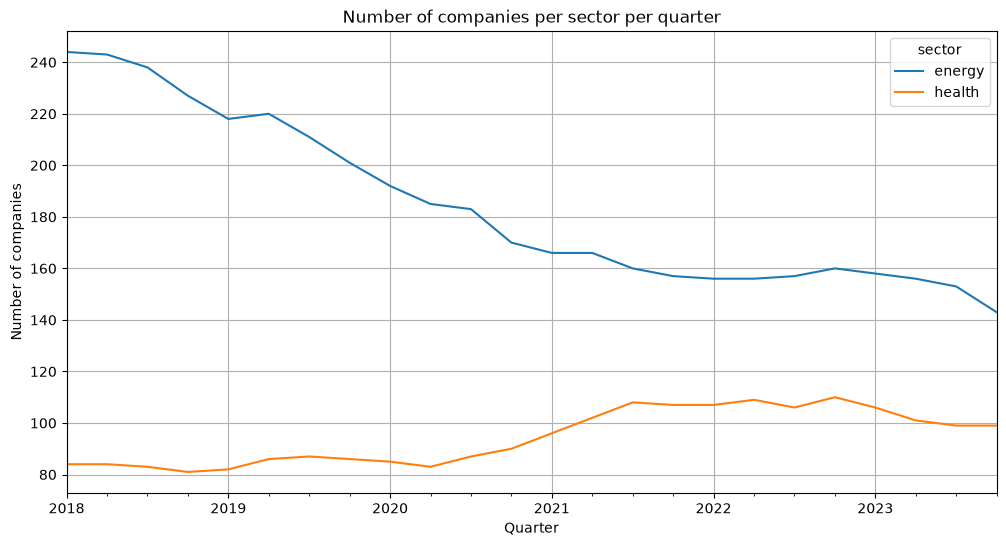

In [46]:
per_quarter = sub.groupby(["quarter", "sector"])["cik"].nunique().unstack()
per_quarter.plot(
    ax=None,
    figsize=(12, 6),
    title="Number of companies per sector per quarter",
    ylabel="Number of companies",
    xlabel="Quarter",
    grid=True,
)
per_quarter

## Paso 2: empresas con presentación en los 24 trimestres

`companies` tiene una fila por empresa: su sector, su primer y su último trimestre con presentación, y la cantidad de trimestres distintos con presentación (`quarters`).

In [47]:
companies = sub.groupby("cik").agg(
    sector=("sector", "first"),
    first=("quarter", "min"),
    last=("quarter", "max"),
    quarters=("quarter", "nunique"),
)
companies["all"] = companies["quarters"] == 24
# companies


survivorship_df = companies.groupby("sector")["all"].agg(survivors="sum", total="count")
survivorship_df["survivorship"] = (
    survivorship_df["survivors"] / survivorship_df["total"] * 100
).round(1)

survivorship_df

,survivors,total,survivorship
sector,,,
energy,101,303,33.3
health,42,169,24.9


## Paso 3: por qué quedan afuera

Cada empresa sin los 24 trimestres cae en un grupo:

- **Entra tarde:** su primera presentación es posterior a 2018Q1. Por ejemplo, sale a bolsa después.
- **Sale antes:** su última presentación es anterior a 2023Q4. Por ejemplo, quiebra o la compran. Este grupo es el sesgo de supervivencia.
- **Ambas:** entra tarde y sale antes.
- **Huecos:** está en 2018Q1 y en 2023Q4, pero le falta algún trimestre del medio.

In [48]:
# companies["all"] = companies["quarters"] == 24


companies.head(2)

,sector,first,last,quarters,all
cik,,,,,
1000229,energy,2018Q1,2023Q1,21,False
1001614,energy,2018Q1,2023Q4,24,True


In [49]:
out = companies[~companies["all"]]
late = out["first"] > pd.Period("2018Q1")
early = out["last"] < pd.Period("2023Q4")
group = pd.Series("huecos", index=out.index)
group[late] = "entra tarde"
group[early] = "sale antes"
group[late & early] = "ambas"


pd.crosstab(group, out["sector"], margins=True)

sector,energy,health,All
row_0,,,
ambas,24,32,56
entra tarde,35,53,88
huecos,7,4,11
sale antes,136,38,174
All,202,127,329


## Resultado

- **Paso 1.** Energía baja de 244 empresas en 2018Q1 a 143 en 2023Q4. Salud sube de 84 a 99.
- **Paso 2.** Con los 24 trimestres quedan 101 de 303 empresas de energía (33%) y 42 de 169 de salud (25%).
- **Paso 3.** En energía, 136 de las 202 empresas que quedan afuera salen antes de 2023Q4. En salud, el grupo más grande es "entra tarde" (53 de 127).

PRECAUCIÓN: en energía, exigir los 24 trimestres elimina sobre todo a las empresas que dejan de presentar. El panel resultante tiene sesgo de supervivencia.